# AtomGPT Detector — Direct UI Report

This notebook analyses the results produced by running the **AtomGPT hallucination detector through its web UI** (not the API) on the 100 confirmed hallucinated citations from the GPTZero NeurIPS 2025 benchmark.

The UI exports a CSV (`hallucination_report_2.csv`) with columns:
`index, status, composite, title_score, author_score, journal_score, year_match, best_match, reference`.

Note: the UI calls the composite score column `composite`; we rename it to `score` so the analysis matches the API notebook.

In [1]:
!pip install pandas matplotlib numpy

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Load the UI results CSV

Upload `hallucination_report_2.csv` to the Colab session (or adjust the path), then load it.

In [4]:
# Load the CSV downloaded from the AtomGPT UI
df = pd.read_csv("hallucination_report_2.csv")

# UI names the composite column 'composite'; rename to 'score' for consistency
df = df.rename(columns={"composite": "score"})

print(f"Loaded {len(df)} rows")
print("Columns:", df.columns.tolist())
df.head()

Loaded 100 rows
Columns: ['index', 'status', 'score', 'title_score', 'author_score', 'journal_score', 'year_match', 'best_match', 'reference']


,index,status,score,title_score,author_score,journal_score,year_match,best_match,reference
0,1,partial,75.0,100.0,0.0,NaN,True,WebVoyager: Building an End-to-End Web Agent w...,"John Doe, Jane Smith. Webvoyager: Building an ..."
1,2,likely hallucinated,41.3,56.0,0.0,51.3,False,Introduction of Virtual Environment with Learn...,"John Smith, Jane Doe. Deep learning techniques..."
2,3,likely hallucinated,48.0,64.1,0.0,NaN,False,Exploring Generative Adversarial Network for I...,"Min-Jun Lee, Soo-Young Kim. Generative adversa..."
3,4,likely hallucinated,43.2,57.5,0.0,NaN,False,AGC-Drive: A Large-Scale Dataset for Real-Worl...,"Firstname Lastname, Others. Drivlme: A large-s..."
4,5,likely hallucinated,35.9,35.9,NaN,NaN,False,Discrete Event System Simulation 5th Edition E...,"Firstname Lastname, Others. Robotslang: Ground..."


In [5]:
# Ensure numeric types for the score columns
num_cols = ["score", "title_score", "author_score", "journal_score"]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Rows the tool actually scored (drop any 'error' rows; UI run has none)
scored = df[df["status"] != "error"].copy()
comp_cols = ["title_score", "author_score", "journal_score"]
print(f"Scored citations: {len(scored)} / {len(df)}")

Scored citations: 100 / 100


## 2. Detection rate and status distribution

In [6]:
STATUS_ORDER = ["likely hallucinated", "partial", "verified", "error"]
counts = df["status"].value_counts().reindex(
    [s for s in STATUS_ORDER if s in df["status"].unique()]
)
print("=== Status distribution (UI) ===")
print(counts.to_string())

detected = df["status"].isin(["likely hallucinated", "partial"]).sum()
print(f"\nDetected (likely hallucinated + partial): {detected}/{len(df)} "
      f"= {100*detected/len(df):.0f}% detection rate")
print(f"Mean composite score: {df['score'].mean():.1f} "
      f"(median {df['score'].median():.1f}, std {df['score'].std():.1f})")

=== Status distribution (UI) ===
status
likely hallucinated    66
partial                28
verified                6

Detected (likely hallucinated + partial): 94/100 = 94% detection rate
Mean composite score: 46.7 (median 51.6, std 26.5)


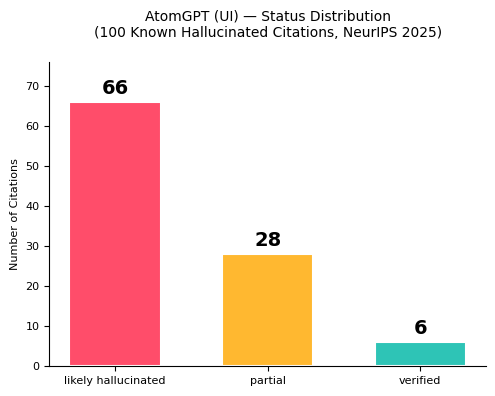

In [7]:
# Status distribution bar plot
COLORS = {
    "likely hallucinated": "#FF4D6A",
    "partial": "#FFB830",
    "verified": "#2EC4B6",
    "error": "#999999",
}
plt.rcParams.update({"figure.dpi": 100, "font.size": 8,
                     "axes.spines.top": False, "axes.spines.right": False})

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(counts.index, counts.values,
              color=[COLORS[s] for s in counts.index],
              edgecolor="white", linewidth=1.5, width=0.6)
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            str(val), ha="center", va="bottom", fontweight="bold", fontsize=14)
ax.set_ylabel("Number of Citations")
ax.set_title("AtomGPT (UI) — Status Distribution\n(100 Known Hallucinated Citations, NeurIPS 2025)\n",
             fontsize=10)
ax.set_ylim(0, counts.max() + 10)
plt.tight_layout()
plt.savefig("ui_status_distribution.png", bbox_inches="tight")
plt.show()

## 3. Composite score by status

In [8]:
print("=== Composite score by status ===")
print(scored.groupby("status")["score"].describe().round(1))

=== Composite score by status ===
                     count  mean   std   min   25%   50%   75%    max
status                                                               
likely hallucinated   66.0  33.3  22.0   0.0   0.0  42.3  51.2   59.4
partial               28.0  69.4   5.6  60.0  63.9  70.8  75.0   75.2
verified               6.0  88.5   9.0  80.9  83.3  83.4  95.8  100.0


## 4. Per-field component analysis

Each component score (0–100) measures how well the fabricated citation matches the closest real paper the tool found, on that field. Author and journal scores exist only when those fields were extracted, so sample sizes differ.

In [9]:
# A. Overall component distribution
print("=== Component score distribution (scored citations) ===")
print(scored[comp_cols].describe().round(1))

=== Component score distribution (scored citations) ===
       title_score  author_score  journal_score
count        100.0          78.0           44.0
mean          62.4           8.0           38.9
std           34.2          19.5           25.9
min            0.0           0.0            0.0
25%           53.2           0.0           21.1
50%           70.1           0.0           37.6
75%           91.4           0.0           52.6
max          100.0         100.0          100.0


In [10]:
# B. Availability (how many citations had each field extracted)
print("=== Availability (component present) ===")
for c in comp_cols:
    print(f"{c:14s}: {scored[c].notna().sum()}/{len(scored)} present")

=== Availability (component present) ===
title_score   : 100/100 present
author_score  : 78/100 present
journal_score : 44/100 present


In [11]:
# C. year_match breakdown
print("=== year_match ===")
print(scored["year_match"].value_counts(dropna=False))

=== year_match ===
year_match
False    70
NaN      18
True     12
Name: count, dtype: int64


In [12]:
# D. Mean component score by status
print("=== Mean component score by status ===")
print(scored.groupby("status")[comp_cols].mean().round(1))

=== Mean component score by status ===
                     title_score  author_score  journal_score
status                                                       
likely hallucinated         45.9           3.5           34.3
partial                     93.6           8.1           49.3
verified                    98.8          60.4           22.0


In [13]:
# E. Failure pattern in the 'likely hallucinated' citations
flagged = scored[scored["status"] == "likely hallucinated"]
print(f"=== Failure pattern in {len(flagged)} 'likely hallucinated' citations ===")
for c in comp_cols:
    vals = flagged[c].dropna()
    low = (vals < 30).sum()
    print(f"{c:14s}: {low}/{len(vals)} scored <30  (mean {vals.mean():.1f})")

=== Failure pattern in 66 'likely hallucinated' citations ===
title_score   : 18/66 scored <30  (mean 45.9)
author_score  : 45/47 scored <30  (mean 3.5)
journal_score : 11/27 scored <30  (mean 34.3)


## 5. Component distribution figures (one per field)

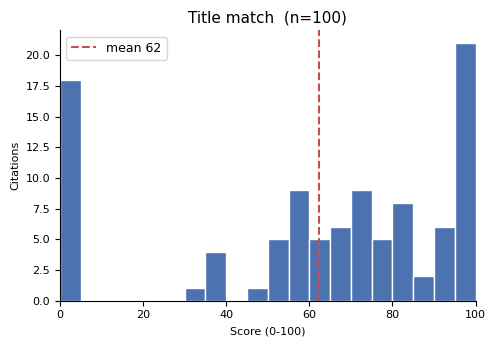

Saved: ui_title_match_dist.png


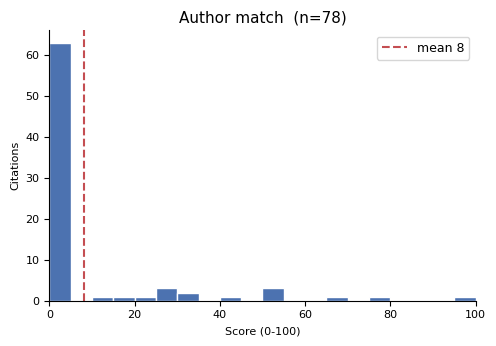

Saved: ui_author_match_dist.png


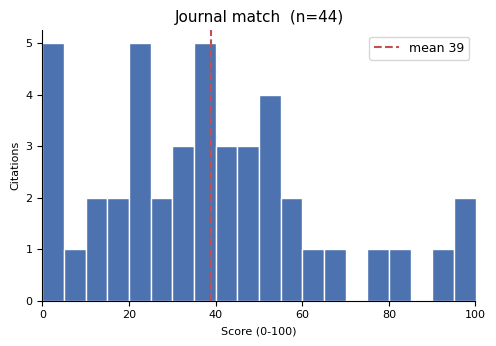

Saved: ui_journal_match_dist.png


In [14]:
panels = [
    ("title_score",   "Title match",   "ui_title_match_dist.png"),
    ("author_score",  "Author match",  "ui_author_match_dist.png"),
    ("journal_score", "Journal match", "ui_journal_match_dist.png"),
]
for col, label, fname in panels:
    vals = scored[col].dropna()
    fig, ax = plt.subplots(figsize=(5, 3.5))
    ax.hist(vals, bins=20, range=(0, 100), color="#4C72B0", edgecolor="white")
    ax.axvline(vals.mean(), color="#C44E52", ls="--", lw=1.5,
               label=f"mean {vals.mean():.0f}")
    ax.set_title(f"{label}  (n={len(vals)})", fontsize=11)
    ax.set_xlabel("Score (0-100)")
    ax.set_ylabel("Citations")
    ax.set_xlim(0, 100)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", fname)

## 6. Mean component score by status (grouped bars)

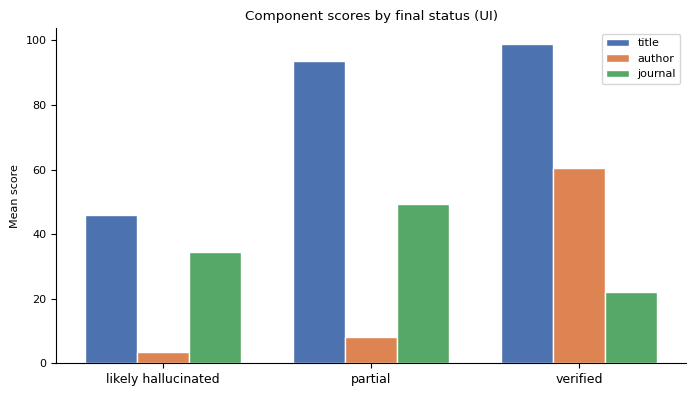

In [15]:
grp = scored.groupby("status")[comp_cols].mean()
order = [s for s in ["likely hallucinated", "partial", "verified"] if s in grp.index]
grp = grp.reindex(order)

x = np.arange(len(grp)); w = 0.25
fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#4C72B0", "#DD8452", "#55A868"]
for i, c in enumerate(comp_cols):
    ax.bar(x + i*w, grp[c], w, label=c.replace("_score", ""),
           color=colors[i], edgecolor="white")
ax.set_xticks(x + w)
ax.set_xticklabels(grp.index, fontsize=9)
ax.set_ylabel("Mean score")
ax.set_title("Component scores by final status (UI)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("ui_component_by_status.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Save the cleaned results

In [16]:
df.to_csv("ui_all_cols_results.csv", index=False)
print("Saved: ui_all_cols_results.csv")

Saved: ui_all_cols_results.csv
